# Практическая работа № 2 — разведочный анализ Titanic

**Студент:** Райымбердиев Исхак  
**Уровень:** B

Цель: исследовать качество данных, распределения, выбросы, связи признаков и дисбаланс целевого класса `survived`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

candidates = [Path('titanic.csv'), Path('practice-2/titanic.csv')]
DATA_PATH = next((path for path in candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Не найден titanic.csv')
df = pd.read_csv(DATA_PATH)
print(f'Файл: {DATA_PATH.resolve()}')
print(f'Размер: {df.shape[0]} строк, {df.shape[1]} столбцов')
df.head()

Файл: /Users/zeus/ML/practice-2/titanic.csv
Размер: 891 строк, 15 столбцов


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Структура, типы и пропуски

In [2]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()
print('Числовые признаки:', numeric_columns)
print('Категориальные признаки:', categorical_columns)
display(pd.DataFrame({
    'dtype': df.dtypes,
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(1),
    'unique': df.nunique(),
}))
print('Полных дубликатов:', df.duplicated().sum())
display(df[numeric_columns].describe().T)

Числовые признаки: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Категориальные признаки: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


,dtype,missing,missing_%,unique
survived,int64,0,0.0,2
pclass,int64,0,0.0,3
sex,str,0,0.0,2
age,float64,177,19.9,88
sibsp,int64,0,0.0,7
parch,int64,0,0.0,7
fare,float64,0,0.0,248
embarked,str,2,0.2,3
class,str,0,0.0,3
who,str,0,0.0,3


Полных дубликатов: 107


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


## Целевая переменная и категориальные признаки

In [3]:
target_counts = df['survived'].value_counts().sort_index()
target_share = df['survived'].value_counts(normalize=True).sort_index()
display(pd.DataFrame({'count': target_counts, 'share': target_share.round(3)}))

for column in ['sex', 'pclass', 'embarked', 'who', 'alone']:
    print(f'\n{column}:')
    display(df[column].value_counts(dropna=False).to_frame('count'))

,count,share
survived,,
0,549,0.616
1,342,0.384



sex:


,count
sex,
male,577
female,314



pclass:


,count
pclass,
3,491
1,216
2,184



embarked:


,count
embarked,
S,644
C,168
Q,77
NaN,2



who:


,count
who,
man,537
woman,271
child,83



alone:


,count
alone,
True,537
False,354


## Распределения и выбросы

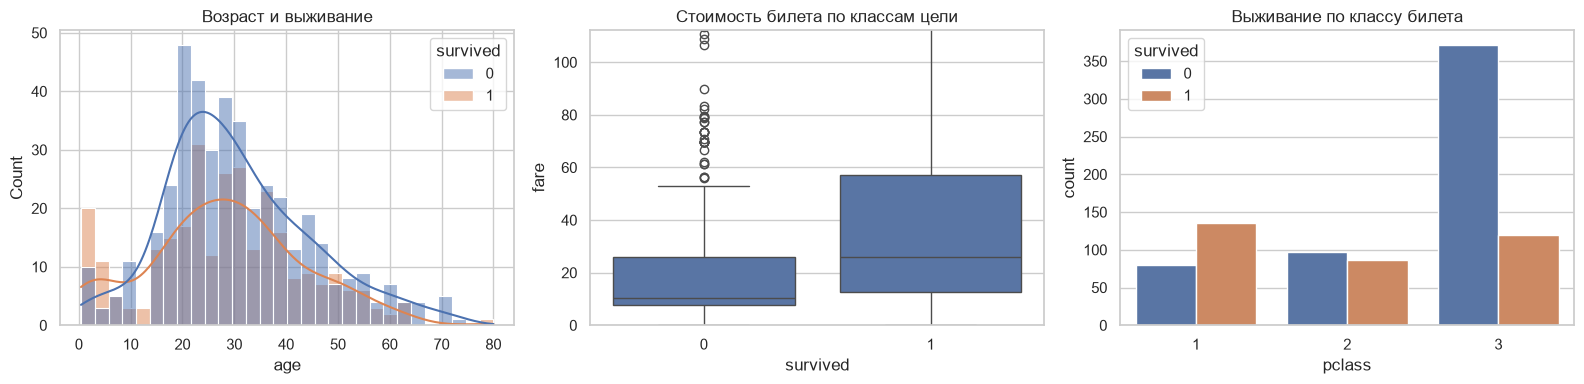

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x='age', hue='survived', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Возраст и выживание')
sns.boxplot(data=df, x='survived', y='fare', ax=axes[1])
axes[1].set_title('Стоимость билета по классам цели')
axes[1].set_ylim(0, df['fare'].quantile(0.95))
sns.countplot(data=df, x='pclass', hue='survived', ax=axes[2])
axes[2].set_title('Выживание по классу билета')
plt.tight_layout()
plt.show()

In [5]:
def iqr_outliers(series):
    clean = series.dropna()
    q1, q3 = clean.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (clean < q1 - 1.5 * iqr) | (clean > q3 + 1.5 * iqr)
    return int(mask.sum())

print('Выбросов age по IQR:', iqr_outliers(df['age']))
print('Выбросов fare по IQR:', iqr_outliers(df['fare']))

Выбросов age по IQR: 11
Выбросов fare по IQR: 116


## Связи признаков

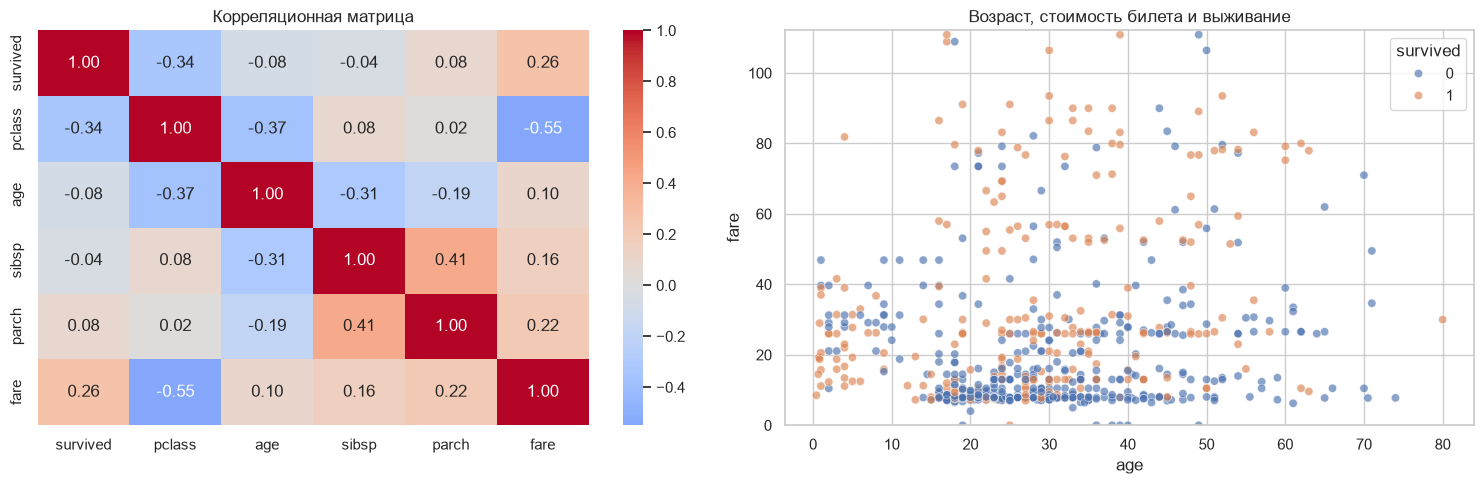

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
corr = df[numeric_columns].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Корреляционная матрица')
sns.scatterplot(data=df, x='age', y='fare', hue='survived', alpha=0.65, ax=axes[1])
axes[1].set_title('Возраст, стоимость билета и выживание')
axes[1].set_ylim(0, df['fare'].quantile(0.95))
plt.tight_layout()
plt.show()

## Выводы

1. В `age` пропущено около 20% значений — для модели их разумно заполнить медианой.
2. В `deck` отсутствует более 75% значений — признак лучше удалить либо выделить категорию `Unknown`.
3. В `embarked` и `embark_town` всего по два пропуска; их можно заполнить наиболее частой категорией.
4. Классы цели несбалансированы умеренно: погибших больше, чем выживших, поэтому кроме accuracy нужны precision, recall и F1.
5. `fare` сильно скошен и содержит выбросы; для некоторых моделей полезны логарифмирование или устойчивое масштабирование.
6. `alive` прямо дублирует целевую переменную `survived` и вызывает утечку данных — его нельзя использовать при обучении.
7. `class` дублирует `pclass`, а `embark_town` — `embarked`; перед моделированием следует оставить по одному признаку из каждой пары.